# Lecture Notes: The Product and Quotient Rules
*Stewart, **Calculus**, 9th ed., §3.2*

**Learning objectives.** By the end of this lecture you should be able to:
1. Explain why $(fg)' \neq f'g'$ and $(f/g)' \neq f'/g'$.
2. Derive the **Product Rule** and the **Quotient Rule** from the limit definition.
3. Apply them to products and quotients of polynomials, powers, and exponentials.
4. Recognize when simplifying first is easier than using either rule.
5. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, t = sp.symbols("x t")

## 1. Where we are

From [§3.1](derivatives_of_polynomials_and_exp_functions.ipynb) we can differentiate sums and constant multiples:

| Function | Derivative |
|---|---|
| $c$ | $0$ |
| $x^n$ | $n x^{n-1}$ |
| $c\,f \pm g$ | $c\,f' \pm g'$ |
| $e^x$ | $e^x$ |

This covers polynomials and exponentials. Products like $x e^x$ and quotients like $\dfrac{e^x}{1+x^2}$ need two new rules.

As in §3.1, the helper below compares a derivative found by hand with SymPy's answer.

In [2]:
def check(f, by_hand, var=x):
    """Display d/dvar f = by_hand and confirm it agrees with SymPy."""
    ok = sp.simplify(sp.diff(f, var) - by_hand) == 0
    display(Math(rf"\frac{{d}}{{d{sp.latex(var)}}}\left({sp.latex(f)}\right) = {sp.latex(by_hand)}"))
    print("Agrees with SymPy:", ok)

## 2. The Product Rule

**Warning:** the derivative of a product is **not** the product of the derivatives. For example, $f(x) = x$ and $g(x) = x^2$ give $(fg)' = (x^3)' = 3x^2$, but $f'g' = 1\cdot 2x = 2x$.

**The Product Rule.** If $f$ and $g$ are both differentiable, then
$$\boxed{\frac{d}{dx}\big[f(x)\,g(x)\big] = f(x)\,\frac{d}{dx}\big[g(x)\big] + g(x)\,\frac{d}{dx}\big[f(x)\big]}$$
In prime notation: $(fg)' = fg' + gf'$. In words: *the first times the derivative of the second, plus the second times the derivative of the first.*

**Proof.** Subtract and add $f(x+h)\,g(x)$ in the numerator:
$$\frac{f(x+h)g(x+h) - f(x)g(x)}{h}
= f(x+h)\,\frac{g(x+h) - g(x)}{h} + g(x)\,\frac{f(x+h) - f(x)}{h}.$$
Let $h \to 0$. Since $f$ is differentiable, it is continuous, so $f(x+h)\to f(x)$. The two difference quotients go to $g'(x)$ and $f'(x)$. $\blacksquare$

**Geometric picture.** Think of $u = f(x)$ and $v = g(x)$ as the sides of a rectangle with area $uv$. When $x$ changes, the change in area is $\Delta(uv) = u\,\Delta v + v\,\Delta u + \Delta u\,\Delta v$. The last term is tiny compared with the others, and it disappears in the limit.

We check the rule for general functions $f$ and $g$:

In [3]:
f, g = sp.Function("f")(x), sp.Function("g")(x)
lhs = sp.diff(f * g, x)
rhs = f * sp.diff(g, x) + g * sp.diff(f, x)
print("Product rule holds:", sp.simplify(lhs - rhs) == 0)

Product rule holds: True


**Example 1.** If $f(x) = x e^x$, find $f'(x)$ and $f^{(n)}(x)$.

*By hand.*
$$f'(x) = x\,(e^x)' + e^x\,(x)' = xe^x + e^x = (x+1)e^x.$$
$$f''(x) = (x+1)e^x + e^x\cdot 1 = (x+2)e^x, \qquad f^{\prime\prime\prime}(x) = (x+3)e^x.$$
Each time we differentiate, the coefficient goes up by one, so $f^{(n)}(x) = (x+n)e^x$.

In [4]:
f = x * sp.exp(x)
check(f, (x + 1) * sp.exp(x))
for k in range(1, 6):
    print(f"f^({k}) = (x+{k})e^x:", sp.simplify(sp.diff(f, x, k) - (x + k) * sp.exp(x)) == 0)

<IPython.core.display.Math object>

Agrees with SymPy: True
f^(1) = (x+1)e^x: True
f^(2) = (x+2)e^x: True
f^(3) = (x+3)e^x: True
f^(4) = (x+4)e^x: True
f^(5) = (x+5)e^x: True


**Example 2.** Differentiate $f(t) = \sqrt{t}\,(a + bt)$, where $a$ and $b$ are constants.

*Method 1 (Product Rule).*
$$f'(t) = \sqrt t\cdot b + (a + bt)\cdot\frac{1}{2\sqrt t} = \frac{2bt + a + bt}{2\sqrt t} = \frac{a + 3bt}{2\sqrt t}.$$

*Method 2 (expand first).* $f(t) = a t^{1/2} + b t^{3/2}$, so $f'(t) = \tfrac12 a t^{-1/2} + \tfrac32 b t^{1/2}$. This is the same answer.

**Lesson:** sometimes simplifying first is faster than using the Product Rule.

In [5]:
a, b = sp.symbols("a b")
check(sp.sqrt(t) * (a + b*t), (a + 3*b*t) / (2 * sp.sqrt(t)), var=t)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 3.** If $f(x) = \sqrt{x}\,g(x)$, where $g(4) = 2$ and $g'(4) = 3$, find $f'(4)$.

*By hand.*
$$f'(x) = \sqrt x\, g'(x) + g(x)\cdot\frac{1}{2\sqrt x}
\quad\Longrightarrow\quad
f'(4) = 2\cdot 3 + 2\cdot\frac14 = 6.5.$$

In [6]:
# f'(4) depends only on g(4) and g'(4), so any g with those values works,
# e.g. the line g(x) = 2 + 3(x - 4).
g = 2 + 3 * (x - 4)
print("f'(4) =", sp.diff(sp.sqrt(x) * g, x).subs(x, 4))

f'(4) = 13/2


## 3. The Quotient Rule

**The Quotient Rule.** If $f$ and $g$ are differentiable and $g(x) \neq 0$, then
$$\boxed{\frac{d}{dx}\left[\frac{f(x)}{g(x)}\right] = \frac{g(x)\,\dfrac{d}{dx}\big[f(x)\big] - f(x)\,\dfrac{d}{dx}\big[g(x)\big]}{\big[g(x)\big]^2}}$$
In prime notation: $\left(\dfrac{f}{g}\right)' = \dfrac{gf' - fg'}{g^2}$. A common way to remember it: *"low d-high minus high d-low, over the square of what's below."*

**The order matters** because of the minus sign. The numerator starts with the denominator $g$.

**Proof.** Let $Q = f/g$. Then
$$\frac{Q(x+h) - Q(x)}{h} = \frac{f(x+h)g(x) - f(x)g(x+h)}{h\,g(x+h)\,g(x)}.$$
Subtract and add $f(x)g(x)$ in the numerator:
$$= \frac{g(x)\,\dfrac{f(x+h)-f(x)}{h} - f(x)\,\dfrac{g(x+h)-g(x)}{h}}{g(x+h)\,g(x)}
\;\xrightarrow{h\to0}\; \frac{g(x)f'(x) - f(x)g'(x)}{g(x)^2},$$
since $g$ is continuous, so $g(x+h) \to g(x)$. $\blacksquare$

In [7]:
f, g = sp.Function("f")(x), sp.Function("g")(x)
lhs = sp.diff(f / g, x)
rhs = (g * sp.diff(f, x) - f * sp.diff(g, x)) / g**2
print("Quotient rule holds:", sp.simplify(lhs - rhs) == 0)

Quotient rule holds: True


**Example 4.** Let $y = \dfrac{x^2 + x - 2}{x^3 + 6}$. Find $y'$.

*By hand.*
$$y' = \frac{(x^3+6)(2x+1) - (x^2+x-2)(3x^2)}{(x^3+6)^2}
= \frac{(2x^4 + x^3 + 12x + 6) - (3x^4 + 3x^3 - 6x^2)}{(x^3+6)^2}
= \frac{-x^4 - 2x^3 + 6x^2 + 12x + 6}{(x^3+6)^2}.$$

In [8]:
y = (x**2 + x - 2) / (x**3 + 6)
check(y, (-x**4 - 2*x**3 + 6*x**2 + 12*x + 6) / (x**3 + 6)**2)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 5.** Find an equation of the tangent line to $y = \dfrac{e^x}{1 + x^2}$ at the point $\left(1, \tfrac{e}{2}\right)$.

*By hand.*
$$y' = \frac{(1+x^2)e^x - e^x(2x)}{(1+x^2)^2} = \frac{e^x(1-x)^2}{(1+x^2)^2}.$$
At $x = 1$, $y' = 0$. The tangent line is horizontal: $y = \dfrac{e}{2}$.

Also notice that $y' \ge 0$ everywhere, so the function is always increasing. It has a horizontal tangent only at $x = 1$.

<IPython.core.display.Math object>

Agrees with SymPy: True
slope at x = 1: 0


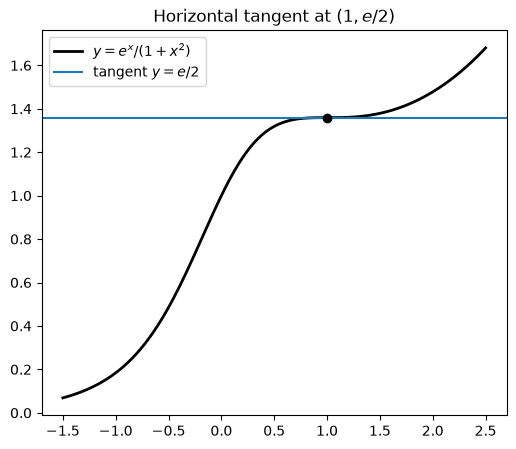

In [9]:
y = sp.exp(x) / (1 + x**2)
check(y, sp.exp(x) * (1 - x)**2 / (1 + x**2)**2)
print("slope at x = 1:", sp.diff(y, x).subs(x, 1))

xs = np.linspace(-1.5, 2.5, 300)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(xs, np.exp(xs) / (1 + xs**2), "k", lw=2, label=r"$y = e^x/(1+x^2)$")
ax.axhline(np.e / 2, lw=1.5, label=r"tangent $y = e/2$")
ax.plot(1, np.e / 2, "ko")
ax.legend()
ax.set_title(r"Horizontal tangent at $(1, e/2)$")
plt.show()

**Tip: don't use the Quotient Rule every time you see a quotient.** For example,
$$F(x) = \frac{3x^2 + 2\sqrt x}{x} = 3x + 2x^{-1/2}
\quad\Longrightarrow\quad F'(x) = 3 - x^{-3/2}.$$
Simplifying first is much faster than using the Quotient Rule here.

In [10]:
check((3*x**2 + 2*sp.sqrt(x)) / x, 3 - x**sp.Rational(-3, 2))

<IPython.core.display.Math object>

Agrees with SymPy: True


## 4. A numerical sanity check

Symbolic checks can hide algebra slips if we type the wrong function. As an independent check, we compare each by-hand derivative with a **central difference** $\dfrac{f(x+h) - f(x-h)}{2h}$ at many points.

In [11]:
def numeric_check(f, fprime, a=0.2, b=3.0, step=1e-5):
    fn, dfn = sp.lambdify(x, f, "numpy"), sp.lambdify(x, fprime, "numpy")
    xs = np.linspace(a, b, 200)
    approx = (fn(xs + step) - fn(xs - step)) / (2 * step)
    exact = dfn(xs)
    return np.max(np.abs(approx - exact)) / np.max(np.abs(exact))

tests = {
    r"x e^x": (x * sp.exp(x), (x + 1) * sp.exp(x)),
    r"\frac{x^2+x-2}{x^3+6}": ((x**2 + x - 2) / (x**3 + 6),
                               (-x**4 - 2*x**3 + 6*x**2 + 12*x + 6) / (x**3 + 6)**2),
    r"\frac{e^x}{1+x^2}": (sp.exp(x) / (1 + x**2), sp.exp(x) * (1 - x)**2 / (1 + x**2)**2),
    r"\frac{3x^2 + 2\sqrt{x}}{x}": ((3*x**2 + 2*sp.sqrt(x)) / x, 3 - x**sp.Rational(-3, 2)),
}
for name, (f, fp) in tests.items():
    rel = numeric_check(f, fp)
    display(Math(rf"{name}: \quad \text{{relative error}} \approx {rel:.1e}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 5. Practice problems

Try these by hand first, then run the cell below to check.

1. $g(x) = (x^3 - 2x)\,e^x$
2. $y = (x^2 + 1)(x^3 - x)$ (*do it two ways: Product Rule, then expand first*)
3. $h(t) = \dfrac{e^t}{t^2 + 1}$
4. $y = \dfrac{1 - xe^x}{x + e^x}$
5. Find the tangent line to $y = \dfrac{2x}{x+1}$ at $(1, 1)$.
6. If $f(2) = 10$, $f'(2) = -2$, $g(2) = 3$, and $g'(2) = 4$, find $(fg)'(2)$ and $(f/g)'(2)$.

In [12]:
problems = [
    (x**3 - 2*x) * sp.exp(x),
    (x**2 + 1) * (x**3 - x),
    sp.exp(t) / (t**2 + 1),
    (1 - x*sp.exp(x)) / (x + sp.exp(x)),
]
for i, f in enumerate(problems, 1):
    var = t if f.has(t) else x
    df = sp.diff(f, var)
    df = sp.expand(df) if i == 2 else sp.factor(sp.simplify(df))
    display(Math(rf"\text{{{i}.}}\quad \frac{{d}}{{d{var}}}\left({sp.latex(f)}\right) = {sp.latex(df)}"))

# 5. tangent line
y = 2*x / (x + 1)
m = sp.diff(y, x).subs(x, 1)
display(Math(rf"\text{{5.}}\quad y = {sp.latex(sp.expand(1 + m*(x - 1)))}"))

# 6. product and quotient rules at a point
f2, df2, g2, dg2 = 10, -2, 3, 4
display(Math(rf"\text{{6.}}\quad (fg)'(2) = {f2*dg2 + g2*df2}, \qquad (f/g)'(2) = {sp.latex(sp.Rational(g2*df2 - f2*dg2, g2**2))}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Summary

| Function | Derivative | Rule |
|---|---|---|
| $f\,g$ | $f g' + g f'$ | Product |
| $\dfrac{f}{g}$ | $\dfrac{g f' - f g'}{g^2}$ | Quotient |

**Table of differentiation formulas so far** (§3.1–3.2):
$$\frac{d}{dx}(c) = 0 \qquad \frac{d}{dx}(x^n) = nx^{n-1} \qquad \frac{d}{dx}(e^x) = e^x$$
$$(cf)' = cf' \qquad (f \pm g)' = f' \pm g' \qquad (fg)' = fg' + gf' \qquad \left(\frac{f}{g}\right)' = \frac{gf' - fg'}{g^2}$$

**Key ideas.**
- $(fg)' \neq f'g'$ and $(f/g)' \neq f'/g'$.
- In the Quotient Rule the order matters: the numerator starts with the **denominator** $g$.
- Before using the Product or Quotient Rule, check whether simplifying first is easier.

**Previous:** [§3.1 Derivatives of Polynomials and Exponential Functions](derivatives_of_polynomials_and_exp_functions.ipynb).